In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/.DS_Store
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/val/.DS_Store
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/val/PNEUMONIA/person1947_bacteria_4876.jpeg
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/val/PNEUMONIA/person1946_bacteria_4875.jpeg
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/val/PNEUMONIA/person1952_bacteria_4883.jpeg
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/val/PNEUMONIA/person1954_bacteria_4886.jpeg
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/val/PNEUMONIA/person1951_bacteria_4882.jpeg
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/val/PNEUMONIA/person1946_bacteria_4874.jpeg
/kaggle/input/datasets/paultimothymooney

In [3]:

import os

print("Hello, LungLens!")

print("Datasets available:")
print(os.listdir("/kaggle/input"))


Hello, LungLens!
Datasets available:
['datasets']


In [5]:

import os

print(os.listdir("/kaggle/input"))



['datasets']


In [6]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    if root.count(os.sep) >= 5:
        dirs[:] = []



/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/paultimothymooney
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia


In [7]:

from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia"
)

for split in ["train", "val", "test"]:
    print(f"\n--- {split.upper()} ---")

    for label in ["NORMAL", "PNEUMONIA"]:
        folder = DATA_DIR / split / label

        if folder.exists():
            images = [
                f for f in folder.iterdir()
                if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
            ]
            print(f"{label}: {len(images)} images")
        else:
            print(f"{label}: folder not found")




--- TRAIN ---
NORMAL: folder not found
PNEUMONIA: folder not found

--- VAL ---
NORMAL: folder not found
PNEUMONIA: folder not found

--- TEST ---
NORMAL: folder not found
PNEUMONIA: folder not found


In [8]:

from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia"
)

print("Folders and files inside the dataset:\n")

for item in DATA_DIR.iterdir():
    print(item.name, "->", "Folder" if item.is_dir() else "File")



Folders and files inside the dataset:

chest_xray -> Folder


In [9]:

from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/paultimothymooney/"
    "chest-xray-pneumonia/chest_xray"
)

for split in ["train", "val", "test"]:
    print(f"\n--- {split.upper()} ---")

    for label in ["NORMAL", "PNEUMONIA"]:
        folder = DATA_DIR / split / label

        if folder.exists():
            images = [
                f for f in folder.iterdir()
                if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
            ]
            print(f"{label}: {len(images)} images")
        else:
            print(f"{label}: folder not found")




--- TRAIN ---
NORMAL: 1341 images
PNEUMONIA: 3875 images

--- VAL ---
NORMAL: 8 images
PNEUMONIA: 8 images

--- TEST ---
NORMAL: 234 images
PNEUMONIA: 390 images


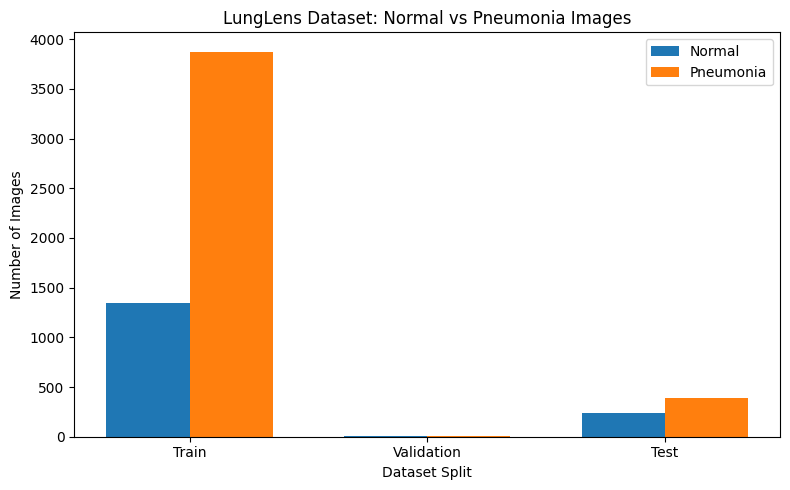

In [10]:
import matplotlib.pyplot as plt
import numpy as np

splits = ["Train", "Validation", "Test"]
normal = [1341, 8, 234]
pneumonia = [3875, 8, 390]

x = np.arange(len(splits))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, normal, width, label="Normal")
plt.bar(x + width/2, pneumonia, width, label="Pneumonia")

plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.title("LungLens Dataset: Normal vs Pneumonia Images")
plt.xticks(x, splits)
plt.legend()
plt.tight_layout()
plt.show()


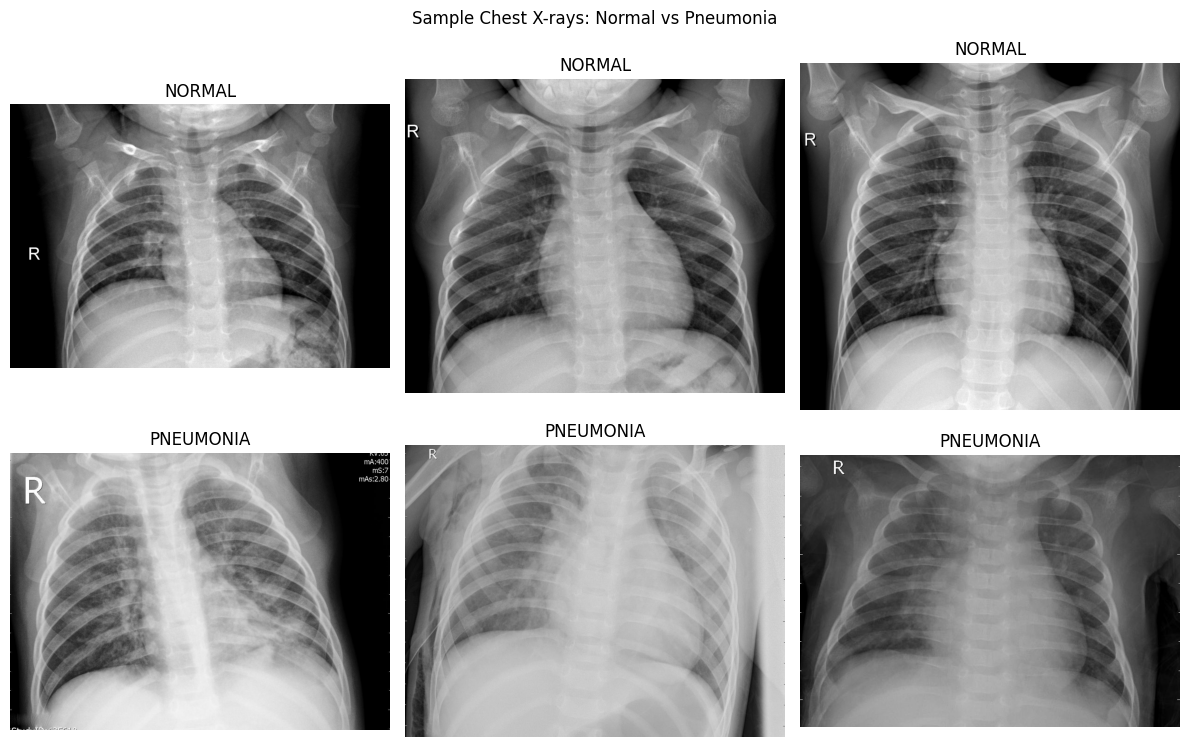

In [26]:

from pathlib import Path
import matplotlib.pyplot as plt
import random
from PIL import Image

DATA_DIR = Path(
    "/kaggle/input/datasets/paultimothymooney/"
    "chest-xray-pneumonia/chest_xray"
)

random.seed(42)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for row, label in enumerate(["NORMAL", "PNEUMONIA"]):
    folder = DATA_DIR / "train" / label
    images = list(folder.glob("*"))
    images = [p for p in images if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
    samples = random.sample(images, 3)

    for col, image_path in enumerate(samples):
        image = Image.open(image_path).convert("RGB")
        axes[row, col].imshow(image, cmap="gray")
        axes[row, col].set_title(label)
        axes[row, col].axis("off")

plt.suptitle("Sample Chest X-rays: Normal vs Pneumonia")
plt.tight_layout()
plt.show()


In [27]:

normal_count = 1341
pneumonia_count = 3875

total = normal_count + pneumonia_count

print("Total training images:", total)
print("Normal images:", round(normal_count / total * 100, 2), "%")
print("Pneumonia images:", round(pneumonia_count / total * 100, 2), "%")


Total training images: 5216
Normal images: 25.71 %
Pneumonia images: 74.29 %


In [28]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.count(os.sep) - "/kaggle/input".count(os.sep)

    if depth <= 3:
        print(root)
        if depth >= 3:
            dirs[:] = []


/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/paultimothymooney
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia
/kaggle/input/datasets/tawsifurrahman
/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database


In [31]:

from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/tawsifurrahman/"
    "covid19-radiography-database"
)

for item in sorted(DATA_DIR.iterdir()):
    print("📁" if item.is_dir() else "📄", item.name)



📁 COVID-19_Radiography_Dataset


In [32]:

from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/tawsifurrahman/"
    "covid19-radiography-database/"
    "COVID-19_Radiography_Dataset"
)

for item in sorted(DATA_DIR.iterdir()):
    print("📁" if item.is_dir() else "📄", item.name)


📁 COVID
📄 COVID.metadata.xlsx
📁 Lung_Opacity
📄 Lung_Opacity.metadata.xlsx
📁 Normal
📄 Normal.metadata.xlsx
📄 README.md.txt
📁 Viral Pneumonia
📄 Viral Pneumonia.metadata.xlsx


In [33]:

from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/tawsifurrahman/"
    "covid19-radiography-database/"
    "COVID-19_Radiography_Dataset"
)

classes = ["COVID", "Lung_Opacity", "Normal", "Viral Pneumonia"]

for label in classes:
    folder = DATA_DIR / label
    images = [
        f for f in folder.iterdir()
        if f.suffix.lower() in [".png", ".jpg", ".jpeg"]
    ]
    print(f"{label}: {len(images)} images")


COVID: 0 images
Lung_Opacity: 0 images
Normal: 0 images
Viral Pneumonia: 0 images


In [34]:

from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/tawsifurrahman/"
    "covid19-radiography-database/"
    "COVID-19_Radiography_Dataset"
)

covid_folder = DATA_DIR / "COVID"

for item in list(covid_folder.iterdir())[:10]:
    print("📁" if item.is_dir() else "📄", item.name)



📁 images
📁 masks


In [35]:

from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/tawsifurrahman/"
    "covid19-radiography-database/"
    "COVID-19_Radiography_Dataset"
)

classes = ["COVID", "Lung_Opacity", "Normal", "Viral Pneumonia"]

for label in classes:
    folder = DATA_DIR / label / "images"

    images = [
        f for f in folder.iterdir()
        if f.suffix.lower() in [".png", ".jpg", ".jpeg"]
    ]

    print(f"{label}: {len(images)} images")


COVID: 3616 images
Lung_Opacity: 6012 images
Normal: 10192 images
Viral Pneumonia: 1345 images


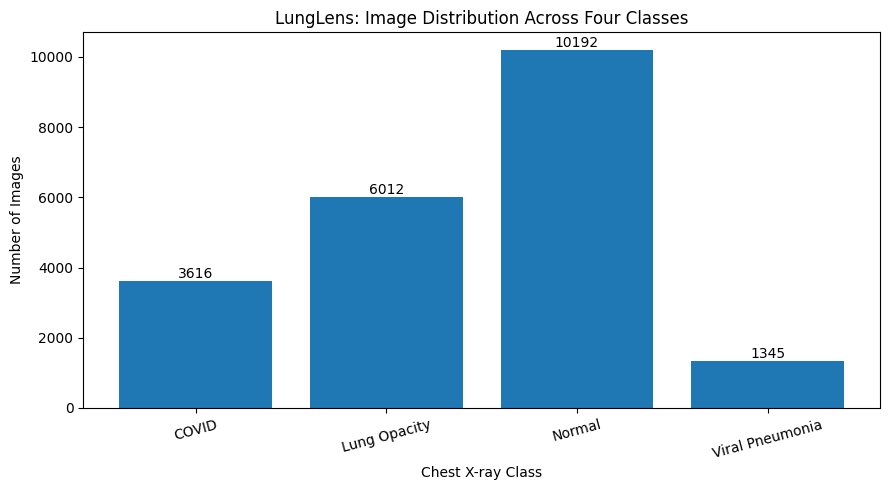

In [38]:

import matplotlib.pyplot as plt

classes = ["COVID", "Lung Opacity", "Normal", "Viral Pneumonia"]
counts = [3616, 6012, 10192, 1345]

plt.figure(figsize=(9, 5))
bars = plt.bar(classes, counts)

plt.title("LungLens: Image Distribution Across Four Classes")
plt.xlabel("Chest X-ray Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)

for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()



In [41]:

from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_DIR = Path(
    "/kaggle/input/datasets/tawsifurrahman/"
    "covid19-radiography-database/"
    "COVID-19_Radiography_Dataset"
)

classes = ["COVID", "Lung_Opacity", "Normal", "Viral Pneumonia"]
image_extensions = {".png", ".jpg", ".jpeg"}

# Collect image paths and class labels
records = []

for label in classes:
    image_folder = DATA_DIR / label / "images"

    for path in image_folder.iterdir():
        if path.is_file() and path.suffix.lower() in image_extensions:
            records.append({
                "image_path": str(path),
                "label": label
            })

df = pd.DataFrame(records)

print("Total images found:", len(df))
print("\nImages per class:")
print(df["label"].value_counts())

# First: 70% training, 30% remaining
train_df, remaining_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

# Then split remaining 30% equally into validation and test
val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=42,
    stratify=remaining_df["label"]
)

print("\nSplit sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nClass counts in each split:")
for name, split_df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{name}")
    print(split_df["label"].value_counts())


Total images found: 21165

Images per class:
label
Normal             10192
Lung_Opacity        6012
COVID               3616
Viral Pneumonia     1345
Name: count, dtype: int64

Split sizes:
Training: 14815
Validation: 3175
Testing: 3175

Class counts in each split:

TRAIN
label
Normal             7134
Lung_Opacity       4208
COVID              2531
Viral Pneumonia     942
Name: count, dtype: int64

VALIDATION
label
Normal             1529
Lung_Opacity        902
COVID               543
Viral Pneumonia     201
Name: count, dtype: int64

TEST
label
Normal             1529
Lung_Opacity        902
COVID               542
Viral Pneumonia     202
Name: count, dtype: int64


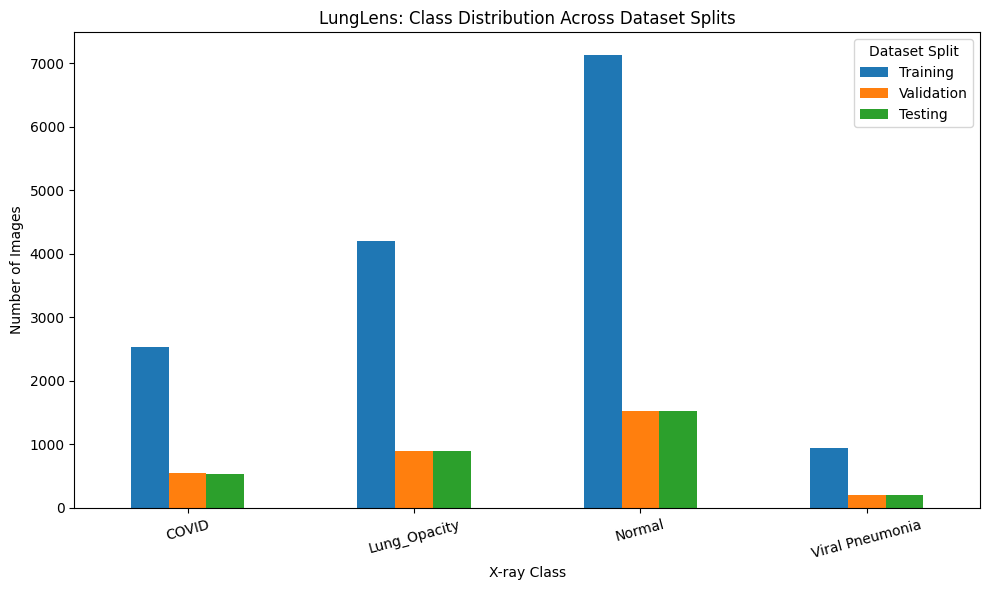

In [42]:

import pandas as pd
import matplotlib.pyplot as plt

split_counts = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
}).fillna(0)

split_counts = split_counts.reindex(classes)

split_counts.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("LungLens: Class Distribution Across Dataset Splits")
plt.xlabel("X-ray Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()


In [45]:

from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/lunglens_splits")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(OUTPUT_DIR / "train.csv", index=False)
val_df.to_csv(OUTPUT_DIR / "validation.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test.csv", index=False)

print("Saved split files:")
for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print(file.name, "-", file.stat().st_size, "bytes")


Saved split files:
test.csv - 441718 bytes
train.csv - 2061053 bytes
validation.csv - 441673 bytes


In [49]:

import shutil

shutil.make_archive(
    "/kaggle/working/lunglens_splits",
    "zip",
    "/kaggle/working/lunglens_splits"
)

print("ZIP file created: /kaggle/working/lunglens_splits.zip")



ZIP file created: /kaggle/working/lunglens_splits.zip


In [50]:
print("TRAIN CSV")
print("Columns:", train_df.columns.tolist())
print("Labels:", sorted(train_df["label"].unique()))

print("\nVALIDATION CSV")
print("Labels:", sorted(val_df["label"].unique()))

print("\nTEST CSV")
print("Labels:", sorted(test_df["label"].unique()))

TRAIN CSV
Columns: ['image_path', 'label']
Labels: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

VALIDATION CSV
Labels: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

TEST CSV
Labels: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']


In [51]:
TRAIN CSV
Columns: ['image_path', 'label']
Labels: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

VALIDATION CSV
Labels: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

TEST CSV
Labels: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

SyntaxError: invalid syntax (1032120305.py, line 1)

In [52]:
print("TRAIN CSV")
print("Columns:", train_df.columns.tolist())
print("Labels:", sorted(train_df["label"].unique()))

print("\nVALIDATION CSV")
print("Labels:", sorted(val_df["label"].unique()))

print("\nTEST CSV")
print("Labels:", sorted(test_df["label"].unique()))

TRAIN CSV
Columns: ['image_path', 'label']
Labels: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

VALIDATION CSV
Labels: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

TEST CSV
Labels: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']


In [ ]:
# Check for exact duplicate image paths across splits

train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

print("Train and validation overlap:", len(train_paths & val_paths))
print("Train and test overlap:", len(train_paths & test_paths))
print("Validation and test overlap:", len(val_paths & test_paths))

print("\nDuplicate paths within each split:")
print("Train:", train_df["image_path"].duplicated().sum())
print("Validation:", val_df["image_path"].duplicated().sum())
print("Test:", test_df["image_path"].duplicated().sum())

In [55]:
# Match the class names to our team's agreed label numbers
label_map = {
    "COVID": 0,
    "Lung_Opacity": 1,
    "Normal": 2,
    "Viral Pneumonia": 3
}

print("Class-to-number mapping:")
for class_name, number in label_map.items():
    print(number, "=", class_name)

print("\nChecking whether all labels are recognized:")
print("Train:", train_df["label"].isin(label_map).all())
print("Validation:", val_df["label"].isin(label_map).all())
print("Test:", test_df["label"].isin(label_map).all())

Class-to-number mapping:
0 = COVID
1 = Lung_Opacity
2 = Normal
3 = Viral Pneumonia

Checking whether all labels are recognized:
Train: True
Validation: True
Test: True


In [56]:
# Check for duplicate image paths across dataset splits

train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

print("Train and validation overlap:", len(train_paths & val_paths))
print("Train and test overlap:", len(train_paths & test_paths))
print("Validation and test overlap:", len(val_paths & test_paths))

print("\nDuplicate paths within each split:")
print("Train:", train_df["image_path"].duplicated().sum())
print("Validation:", val_df["image_path"].duplicated().sum())
print("Test:", test_df["image_path"].duplicated().sum())

Train and validation overlap: 0
Train and test overlap: 0
Validation and test overlap: 0

Duplicate paths within each split:
Train: 0
Validation: 0
Test: 0
